# EDA and data cleaning — Constandino
Concert ticket purchase prediction (DSBA Kaggle challenge).

Part 1 of 2: exploring and cleaning the data. The cleaned data is saved at the end and loaded by `02_feature_engineering_constandino.ipynb`.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import json
with open("../data/raw/music_app.json") as f:
    music = json.load(f)

## Load data

In [2]:
# read train data
user_concert_train = pd.read_csv('../data/raw/train.csv')
user_concert_train.columns.to_list()

# read test data
user_concert_test = pd.read_csv('../data/raw/test.csv')
user_concert_test.columns.to_list()

['row_id',
 'user_id',
 'music_app_user_id',
 'age',
 'education',
 'spending_capacity_band',
 'home_city',
 'home_lat',
 'home_lon',
 'stated_favourite_genre',
 'past_purchase_count',
 'first_timer',
 'typical_ticket_spend',
 'usual_booking_lead_days',
 'concert_id',
 'artist_id',
 'artist_name',
 'genres',
 'venue_city',
 'venue_lat',
 'venue_lon',
 'concert_at',
 'sale_opened_at',
 'prediction_at',
 'ticket_price',
 'booking_fee',
 'discount_pct',
 'event_page_visits_7d',
 'wishlisted',
 'travel_search_city',
 'travel_search_arrival']

In [3]:
sample_submission = pd.read_csv('../data/raw/sample_submission.csv')
sample_submission.columns.to_list()
sample_submission.head()

,row_id,buy
0,R3770C503,0
1,R216C3DE0,0
2,R315CFF39,0
3,R0CC22A1C,0
4,R30EE7196,0


## First look

In [4]:
# EDA 
print(user_concert_train.shape) # 30k observations, 32 columns
print(user_concert_test.shape)  # 20k observations, 31 columns

(30000, 32)
(20000, 31)


In [5]:
#glimpse of data
user_concert_train.head()
user_concert_test.head()

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,concert_at,sale_opened_at,prediction_at,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,travel_search_city,travel_search_arrival
0,R3770C503,U3ACC7254,M0DE861B3,46,undergraduate,1,Lyon,45.764,4.835,folk_country,...,2026-11-10T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,85.00,10.10,0,0.0,0,Lyon,2026-11-10
1,R216C3DE0,U1C2E3AFA,M3B7890DA,47,undergraduate,5,Paris,48.857,2.352,rnb_soul,...,2026-11-10T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,106.25,11.38,0,0.0,1,NaN,NaN
2,R315CFF39,U1593B998,M17CA551F,46,undergraduate,3,Lyon,45.764,4.835,NaN,...,2026-12-12T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,93.75,10.62,10,1.0,0,NaN,NaN
3,R0CC22A1C,U15FCAF27,M1B1E629F,18,secondary,3,Rennes,48.117,-1.678,classical,...,2026-12-12T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,93.75,10.62,20,0.0,0,NaN,NaN
4,R30EE7196,U03D69656,M05B8CCEE,63,postgraduate,1,Lyon,45.764,4.835,alternative,...,2026-11-26T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,112.00,11.72,0,1.0,0,NaN,NaN


In [6]:
print(user_concert_train.groupby("user_id").size().unique()) # uniquen users 5 
print(len(set(user_concert_train.user_id) & set(user_concert_test.user_id))) # 0

[5]
0


every user has exactly 5 rows, and no user appears in both train and test.

## Target balance

In [7]:
# target balance
user_concert_train.buy.value_counts() 
# class imbalance 2:1 on target data

buy
0    19914
1    10086
Name: count, dtype: int64

There's a mild imbalance, nothing crazy. 

In [8]:
#info
user_concert_train.info() 

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   row_id                   30000 non-null  str    
 1   user_id                  30000 non-null  str    
 2   music_app_user_id        28305 non-null  str    
 3   age                      30000 non-null  int64  
 4   education                30000 non-null  str    
 5   spending_capacity_band   30000 non-null  int64  
 6   home_city                30000 non-null  str    
 7   home_lat                 30000 non-null  float64
 8   home_lon                 30000 non-null  float64
 9   stated_favourite_genre   25375 non-null  str    
 10  past_purchase_count      30000 non-null  int64  
 11  first_timer              30000 non-null  int64  
 12  typical_ticket_spend     21760 non-null  float64
 13  usual_booking_lead_days  21760 non-null  float64
 14  concert_id               30000 no

## Summary statistics and extreme values (raw data, before filling the gaps)

In [9]:
user_concert_train.describe() # typical_ticket_spend, usual_booking_lead_days max values look extreme, inspect below

,age,spending_capacity_band,home_lat,home_lon,past_purchase_count,first_timer,typical_ticket_spend,usual_booking_lead_days,venue_lat,venue_lon,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,buy
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,21760.000000,21760.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,29137.000000,30000.00000,30000.000000
mean,41.406667,2.979333,47.303203,1.988091,2.896000,0.274667,141.411673,62.709789,47.461400,1.622200,99.986608,10.999195,4.534667,0.606583,0.16220,0.336200
std,13.884153,1.437118,2.113600,2.589645,2.320423,0.446354,72.679219,46.384167,2.088592,2.359991,27.056185,1.623555,6.723960,0.798631,0.36864,0.472416
min,18.000000,1.000000,43.604000,-1.678000,0.000000,0.000000,20.870000,3.500000,44.838000,-1.554000,60.000000,8.600000,0.000000,0.000000,0.00000,0.000000
25%,30.000000,2.000000,45.764000,-0.579000,0.000000,0.000000,90.937500,31.500000,45.764000,-0.579000,76.000000,9.560000,0.000000,0.000000,0.00000,0.000000
50%,41.000000,3.000000,48.117000,2.352000,3.000000,0.000000,125.462500,50.000000,47.218000,2.352000,95.000000,10.700000,0.000000,0.000000,0.00000,0.000000
75%,53.000000,4.000000,48.857000,3.057000,5.000000,1.000000,175.380000,79.000000,48.857000,3.057000,112.000000,11.720000,10.000000,1.000000,0.00000,1.000000
max,65.000000,5.000000,50.630000,7.752000,13.000000,1.000000,786.915000,497.000000,50.630000,4.835000,175.000000,15.500000,20.000000,6.000000,1.00000,1.000000


typical_ticket_spend (raw)
count 21760, mean 141.41, std 72.68, min 20.87, 25% 90.94, 50% 125.46, 75% 175.38, max 786.915 -- seems huge, have to inspect

usual_booking_lead_days (raw)
count 21760, mean 62.71, std 46.38, min 3.5, 25% 31.5, 50% 50, 75% 79, max 497 -- seems huge, have to inspect

(count is 21760, not 30000: the 8240 first-timers have no value yet, they are filled in the missing values section)

In [10]:
user_concert_train.nlargest(10, "typical_ticket_spend")[["user_id", "spending_capacity_band", "typical_ticket_spend", "past_purchase_count", "ticket_price", "buy"]] # not errors, but they’re extreme
user_concert_train.nlargest(10, "usual_booking_lead_days")[["user_id", "spending_capacity_band", "typical_ticket_spend", "past_purchase_count","usual_booking_lead_days", "ticket_price", "buy"]] # not errors, but they’re extreme

,user_id,spending_capacity_band,typical_ticket_spend,past_purchase_count,usual_booking_lead_days,ticket_price,buy
6632,U04B3BC26,2,146.545,4,497.0,131.25,0
10690,U04B3BC26,2,146.545,4,497.0,95.00,0
17138,U04B3BC26,2,146.545,4,497.0,75.00,0
19788,U04B3BC26,2,146.545,4,497.0,140.00,1
22131,U04B3BC26,2,146.545,4,497.0,85.00,0
1280,U14D3438E,4,233.725,4,467.0,85.00,1
14817,U14D3438E,4,233.725,4,467.0,140.00,1
17167,U14D3438E,4,233.725,4,467.0,95.00,0
21796,U14D3438E,4,233.725,4,467.0,105.00,0
26531,U14D3438E,4,233.725,4,467.0,93.75,1


## Pairplot of numeric columns

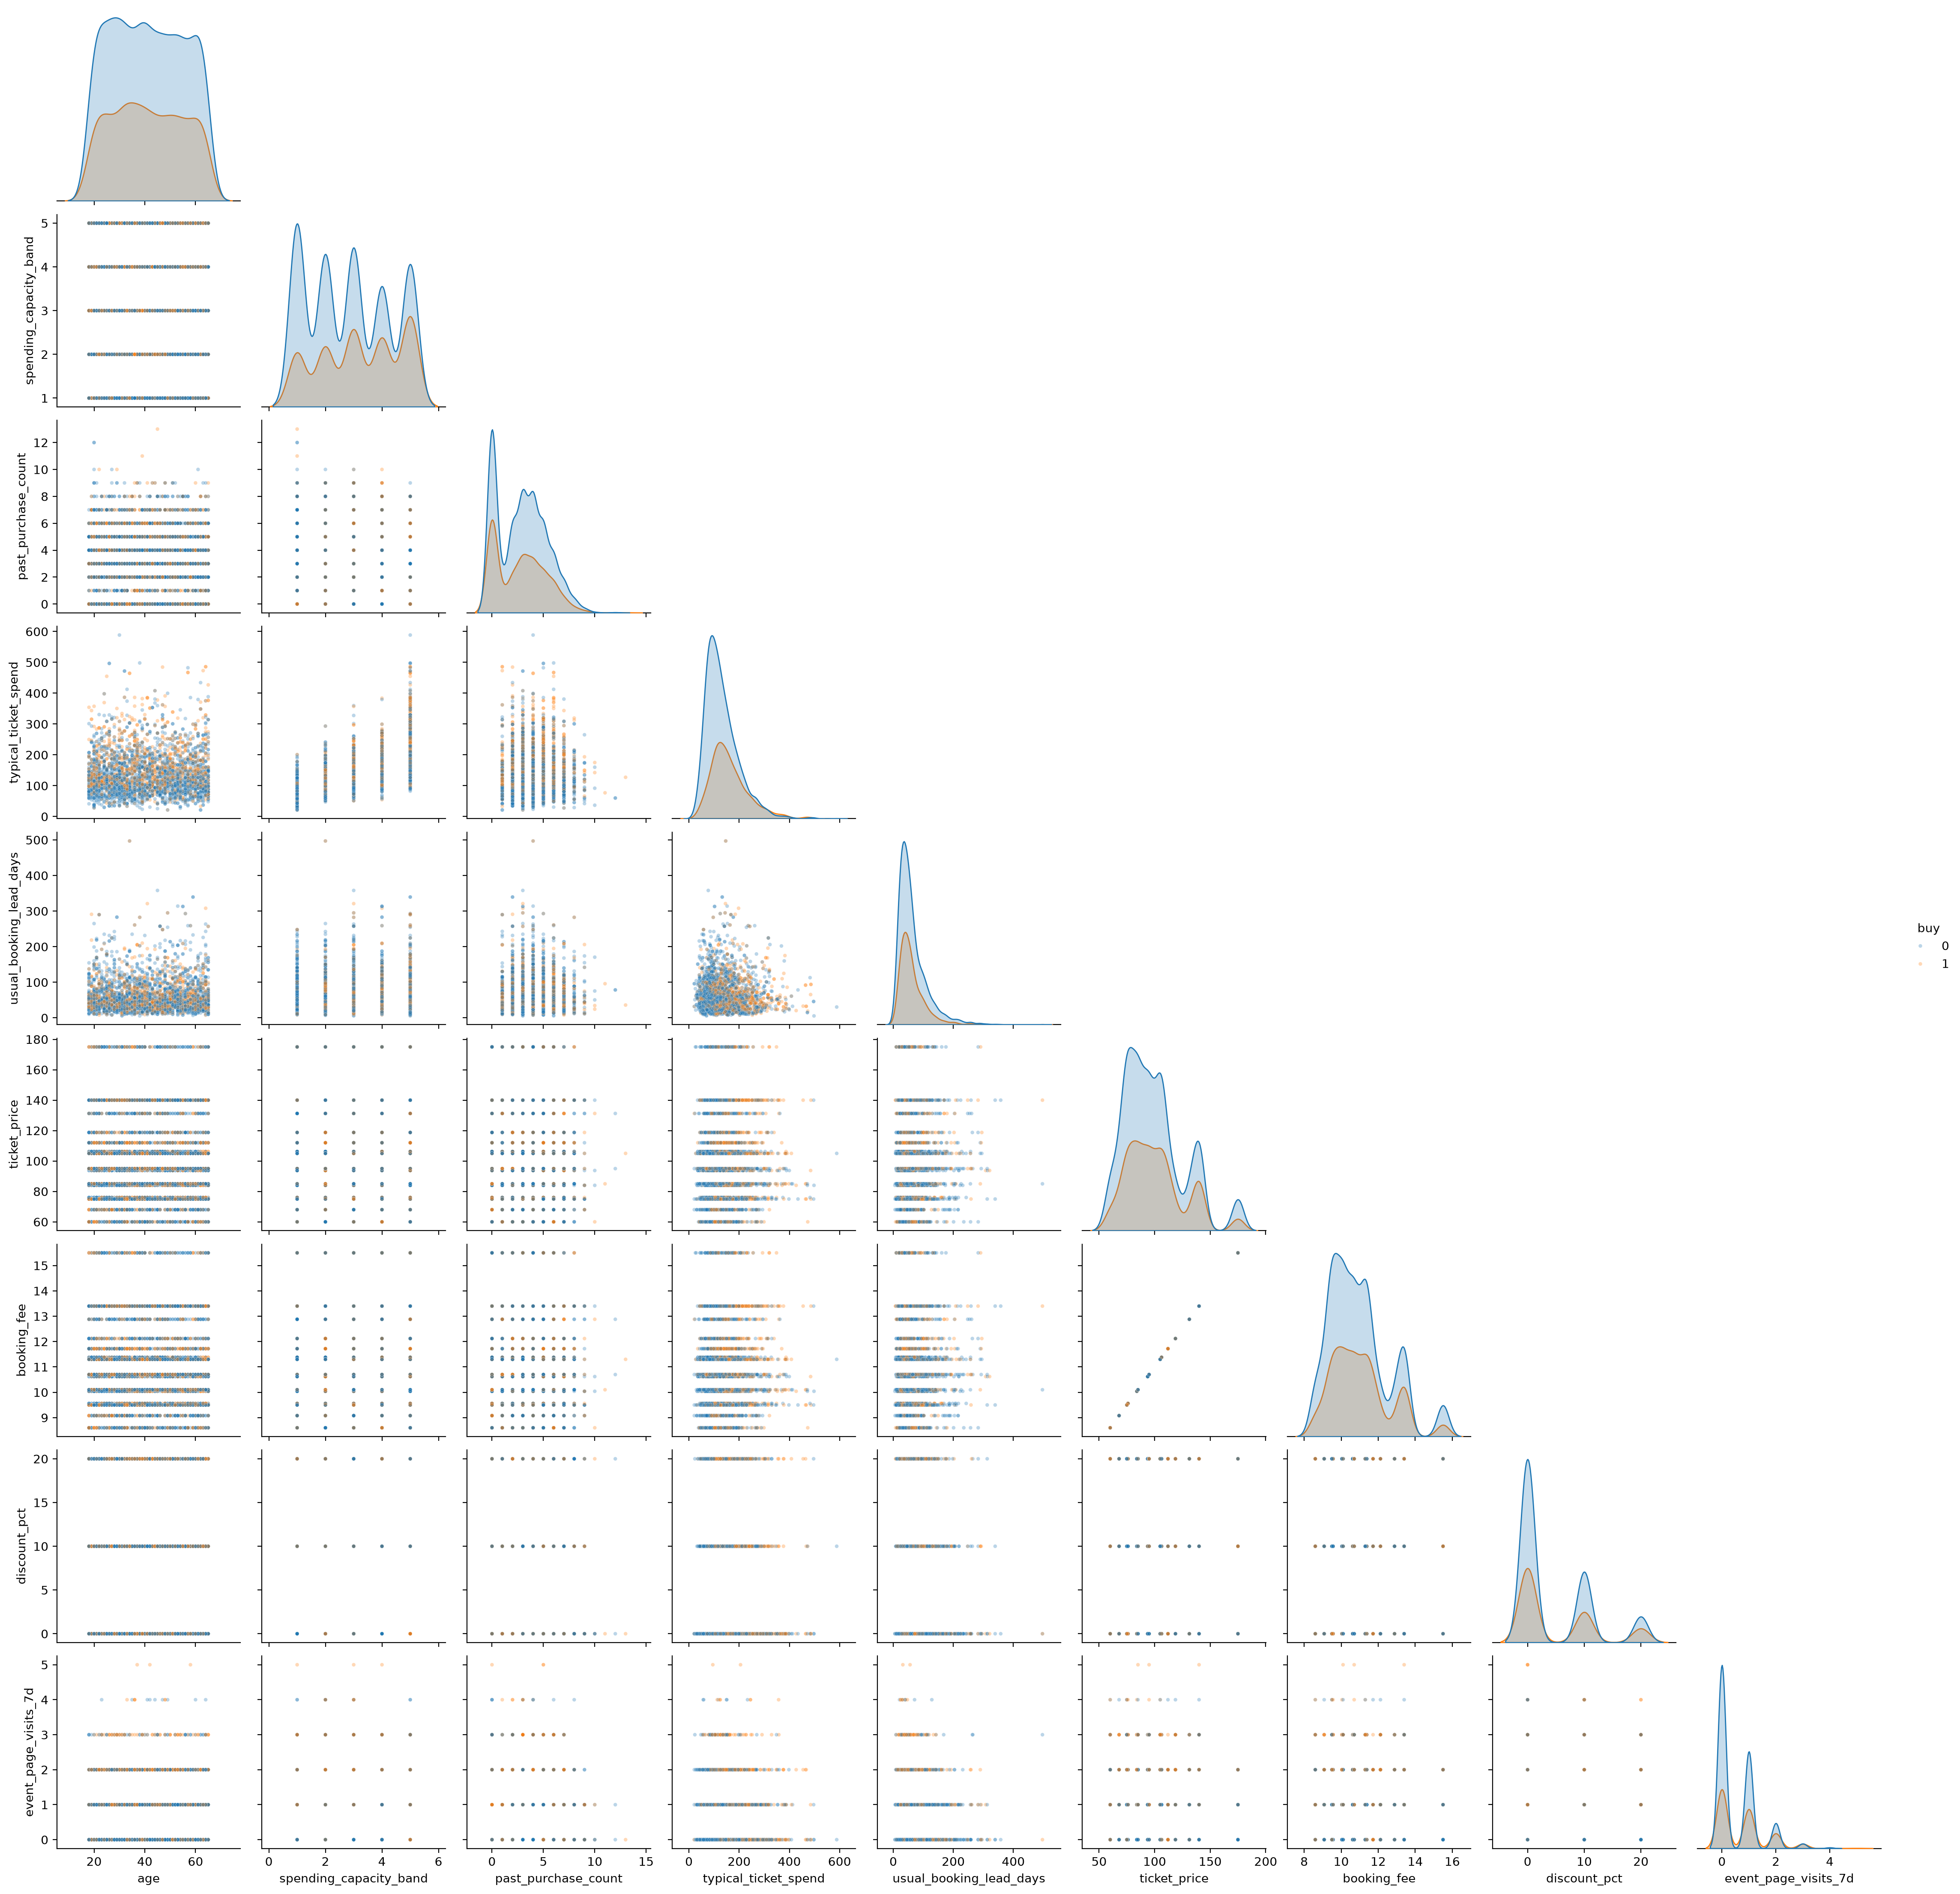

In [11]:
#sb.pairplot(user_concert_train) # check associations ( too large + I dont understand much)
#leave out the 0/1 flags, the IDs and the lat/lon columns, which only show up as rows of dots.

num_cols = ["age", "spending_capacity_band", "past_purchase_count", "typical_ticket_spend",
            "usual_booking_lead_days", "ticket_price", "booking_fee", "discount_pct",
            "event_page_visits_7d"]

sb.pairplot(
    user_concert_train[num_cols + ["buy"]].sample(5000, random_state=0), #using a random sample to avoid 30k rows
    hue="buy", corner=True, plot_kws={"alpha": 0.3, "s": 10},
)

Observations from the pairplot:
- a,booking fee and ticket price form a perfect line, so booking fee is an exact copy: drop it. Anything that doesnt show a relationship in the plot wont be omitted.
- b,The higher someone’s spending capacity band, the more likely they are to buy.
- c,Buyers tend to have a higher typical ticket spend.
- d,More event page visits go with more buying.

## Drop booking_fee

In [12]:
# booking_fee is an exact copy of ticket_price, ill drop it since correlation is exact
user_concert_train = user_concert_train.drop(columns=["booking_fee"])
user_concert_test = user_concert_test.drop(columns=["booking_fee"])

## Missing values

In [13]:
# find missing values
user_concert_train.isnull().sum()  # 7 columns with gaps, check why they are missing

row_id                         0
user_id                        0
music_app_user_id           1695
age                            0
education                      0
spending_capacity_band         0
home_city                      0
home_lat                       0
home_lon                       0
stated_favourite_genre      4625
past_purchase_count            0
first_timer                    0
typical_ticket_spend        8240
usual_booking_lead_days     8240
concert_id                     0
artist_id                      0
artist_name                    0
genres                         0
venue_city                     0
venue_lat                      0
venue_lon                      0
concert_at                     0
sale_opened_at                 0
prediction_at                  0
ticket_price                   0
discount_pct                   0
event_page_visits_7d         863
wishlisted                     0
travel_search_city         22496
travel_search_arrival      22496
buy       

analyse why we have missing values and if they are random or not

### 1. music_app_user_id

In [14]:
#1. music_app_user_id
# count the percentage of rows that buy, grouped by non music app/music app user (True = no music app)
print(user_concert_train.groupby(user_concert_train["music_app_user_id"].isna())["buy"].mean())


music_app_user_id
False    0.326762
True     0.493805
Name: buy, dtype: float64


We find out that people without an id buy much more (49% vs 33%).. the json file contains the accounts so lets see what we can find there..

In [15]:
# open the dictionary in pretty print style
from rich.pretty import pprint
pprint(music, max_length=20, max_string=40)

{
│   'schema_version': '1.0',
│   'history_ends_before': '2026-10-01T00:00:00Z',
│   'catalog': {
│   │   'genres': [
│   │   │   'hip_hop',
│   │   │   'rnb_soul',
│   │   │   'jazz_funk',
│   │   │   'pop',
│   │   │   'pop_rock',
│   │   │   'alternative',
│   │   │   'electronic',
│   │   │   'folk_country',
│   │   │   'psychedelic',
│   │   │   'classical',
│   │   │   'metal'
│   │   ],
│   │   'artists': [
│   │   │   {
│   │   │   │   'artist_id': 'A01',
│   │   │   │   'artist_name': 'Kendrick Lamar',
│   │   │   │   'genres': ['hip_hop', 'rnb_soul', 'jazz_funk', 'pop']
│   │   │   },
│   │   │   {
│   │   │   │   'artist_id': 'A02',
│   │   │   │   'artist_name': 'Olivia Rodrigo',
│   │   │   │   'genres': ['pop', 'pop_rock', 'alternative']
│   │   │   },
│   │   │   {
│   │   │   │   'artist_id': 'A03',
│   │   │   │   'artist_name': 'Taylor Swift',
│   │   │   │   'genres': ['pop', 'pop_rock', 'alternative', 'folk_country']
│   │   │   },
│   │   │   {
│   │   │   │   'ar

Notice there is an activity status within music app user id... so we have an extra layer there to categorize these users , along with sessions and tracks, this is a new attribute or a new leaf that might come in handy that before we did not take into account, (i did has account and has not account before as a feature, now theres more info)

In [16]:
# one row per account: id, status, number of sessions, number of plays
acc = pd.DataFrame({
    "music_app_user_id": [a["music_app_user_id"] for a in music["accounts"]], ## the account’s id, the key that links to music_app_user_id in train/test
    "activity_status":   [a["activity_status"] for a in music["accounts"]], ## the status written in the JSON: "active", "empty" or "missing"
    "n_sessions":        [len(a["sessions"]) for a in music["accounts"]], ## how many listening sessions the account has.. len counts the items in the sessions list
    "n_plays":           [sum(len(s["tracks"]) for s in a["sessions"]) for a in music["accounts"]], ## total songs played across all sessions
})
acc.head()


,music_app_user_id,activity_status,n_sessions,n_plays
0,M1213C172,active,53,82
1,M2B19FDA8,active,61,100
2,M24E86338,active,42,54
3,M27ADBF54,active,32,39
4,M2136A90A,active,36,47


In [17]:
## lets see what we can get in terms of descriptive statistics ( i choose number of accounts) for each category in activity status
acc.groupby("activity_status")[["n_sessions", "n_plays"]].agg(["count", "mean", "max"])

n_sessions                n_plays                
                     count       mean max   count       mean  max
activity_status                                                  
active                8746  44.323119  69    8746  63.103247  100
empty                  379   0.000000   0     379   0.000000    0
missing                307   0.000000   0     307   0.000000    0

Empty and missing accounts have 0 sessions and 0 plays: they never listened. 
 I will join activity_status to train and test as music_app_status to get extra layer of info

In [18]:
# add the activity status as music_app_status to train and test (no id -> "no_account")
for df in [user_concert_train, user_concert_test]:
    df["music_app_status"] = df["music_app_user_id"].map(acc.set_index("music_app_user_id")["activity_status"]).fillna("no_account")
user_concert_train["music_app_status"].value_counts()

music_app_status
active        26180
no_account     1695
empty          1190
missing         935
Name: count, dtype: int64

this shows that only active accounts have any listening at all.

Now the step that matters for predicting, is to see if listening to the concert’s artist go along with buying

In [19]:
# buy rate per account status
user_concert_train.groupby("music_app_status")["buy"].agg(["mean", "size"]).round(3)

,mean,size
music_app_status,,
active,0.312,26180
empty,0.499,1190
missing,0.509,935
no_account,0.494,1695


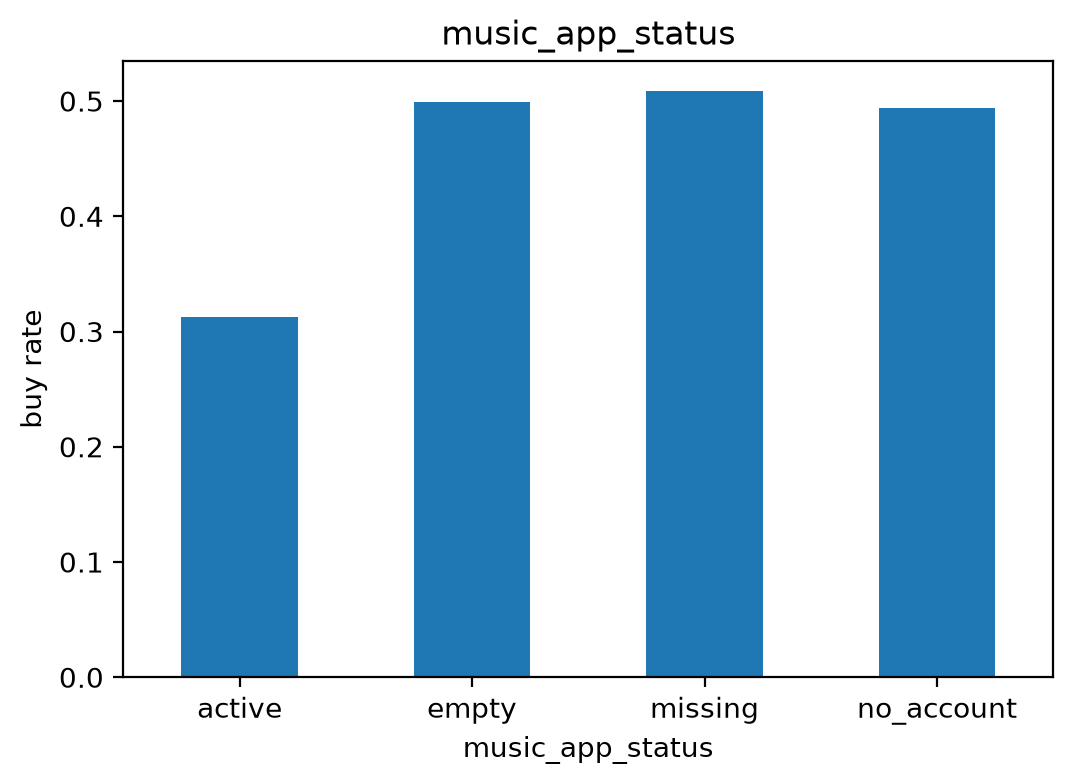

In [20]:
user_concert_train.groupby("music_app_status")["buy"].mean().plot(
    kind="bar", title="music_app_status", ylabel="buy rate", rot=0, figsize=(6, 4)
)
plt.show()

Verdict: Only active accounts buy less than average (31%). Empty, missing and no account all buy about 50%, almost the same as each other. What matters isn’t whether someone has a music app id (like what we did before in our EDA...) but whether they actually listen on it.

Decision: keep music_app_status (4 levels) instead of the yes/no has_music_app flag,

## Next question: among active users, does what they listen to matter?

In [21]:
# all plays in one table: one row per song played
plays = pd.json_normalize(music["accounts"], record_path=["sessions", "tracks"],
                          meta=["music_app_user_id"])
plays["minutes"] = plays["played_ms"] / 60000
print(f"{len(plays):,} plays")
plays.head()

551,901 plays


,played_at,artist_id,genre,track_id,played_ms,track_ms,source,saved,music_app_user_id,minutes
0,2026-09-30T21:22:16Z,A11,alternative,A11_6,132490,160000,autoplay,False,M1213C172,2.208167
1,2026-09-29T00:22:53Z,A08,jazz_funk,A08_6,198000,198000,autoplay,False,M1213C172,3.300000
2,2026-09-28T00:42:34Z,A08,jazz_funk,A08_12,223698,273000,search,True,M1213C172,3.728300
3,2026-09-28T17:59:57Z,A11,alternative,A11_12,205737,232000,search,False,M1213C172,3.428950
4,2026-09-27T21:36:03Z,A16,metal,A16_10,180541,196000,search,False,M1213C172,3.009017


In [22]:
# check: plays contains every play of every account
print("plays in the table:", len(plays))
print("plays counted per account:", acc["n_plays"].sum())               # should be the same number
print("accounts in plays:", plays["music_app_user_id"].nunique())  # should be 8,746 = the active ones
print("time range:", plays["played_at"].min(), "===", plays["played_at"].max())

plays in the table: 551901
plays counted per account: 551901
accounts in plays: 8746
time range: 2026-07-03T00:00:03Z === 2026-09-30T22:12:37Z


I build a temporary table active (active users only) with artist_share, just to check whether listening goes with buying. The real music features for train and test are built in feature engineering.

In [23]:
# share of each user's listening time that goes to each artist
artist_min = plays.groupby(["music_app_user_id", "artist_id"])["minutes"].sum()
total_min  = plays.groupby("music_app_user_id")["minutes"].sum()
share = artist_min.div(total_min, level="music_app_user_id").rename("artist_share").reset_index()

# add it to the active users' rows; no match = never played this artist = 0
active = user_concert_train[user_concert_train["music_app_status"] == "active"]
active = active.merge(share, on=["music_app_user_id", "artist_id"], how="left").fillna({"artist_share": 0})

In [24]:
active.head()

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,prediction_at,ticket_price,discount_pct,event_page_visits_7d,wishlisted,travel_search_city,travel_search_arrival,buy,music_app_status,artist_share
0,R2F019957,U2CFDCAAD,M1B01D2D7,23,postgraduate,2,Nantes,47.218,-1.554,pop,...,2026-10-01T00:00:00Z,75.0,0,0.0,1,NaN,NaN,0,active,0.000000
1,R0804D93A,U1FC01010,M1B2C63CC,51,undergraduate,5,Bordeaux,44.838,-0.579,pop,...,2026-10-01T00:00:00Z,85.0,0,3.0,0,NaN,NaN,1,active,0.172106
2,R367FE81E,U0C605712,M3AEF638D,32,secondary,1,Lyon,45.764,4.835,classical,...,2026-10-01T00:00:00Z,175.0,20,1.0,1,NaN,NaN,0,active,0.005324
3,R344BBE29,U25D1DD8A,M00C580ED,24,secondary,2,Paris,48.857,2.352,jazz_funk,...,2026-10-01T00:00:00Z,84.0,0,1.0,1,NaN,NaN,1,active,0.004777
4,R004ABDEB,U1600BC92,M29AC37E6,21,secondary,3,Bordeaux,44.838,-0.579,NaN,...,2026-10-01T00:00:00Z,95.0,0,0.0,0,Rennes,2026-12-28,1,active,0.076928


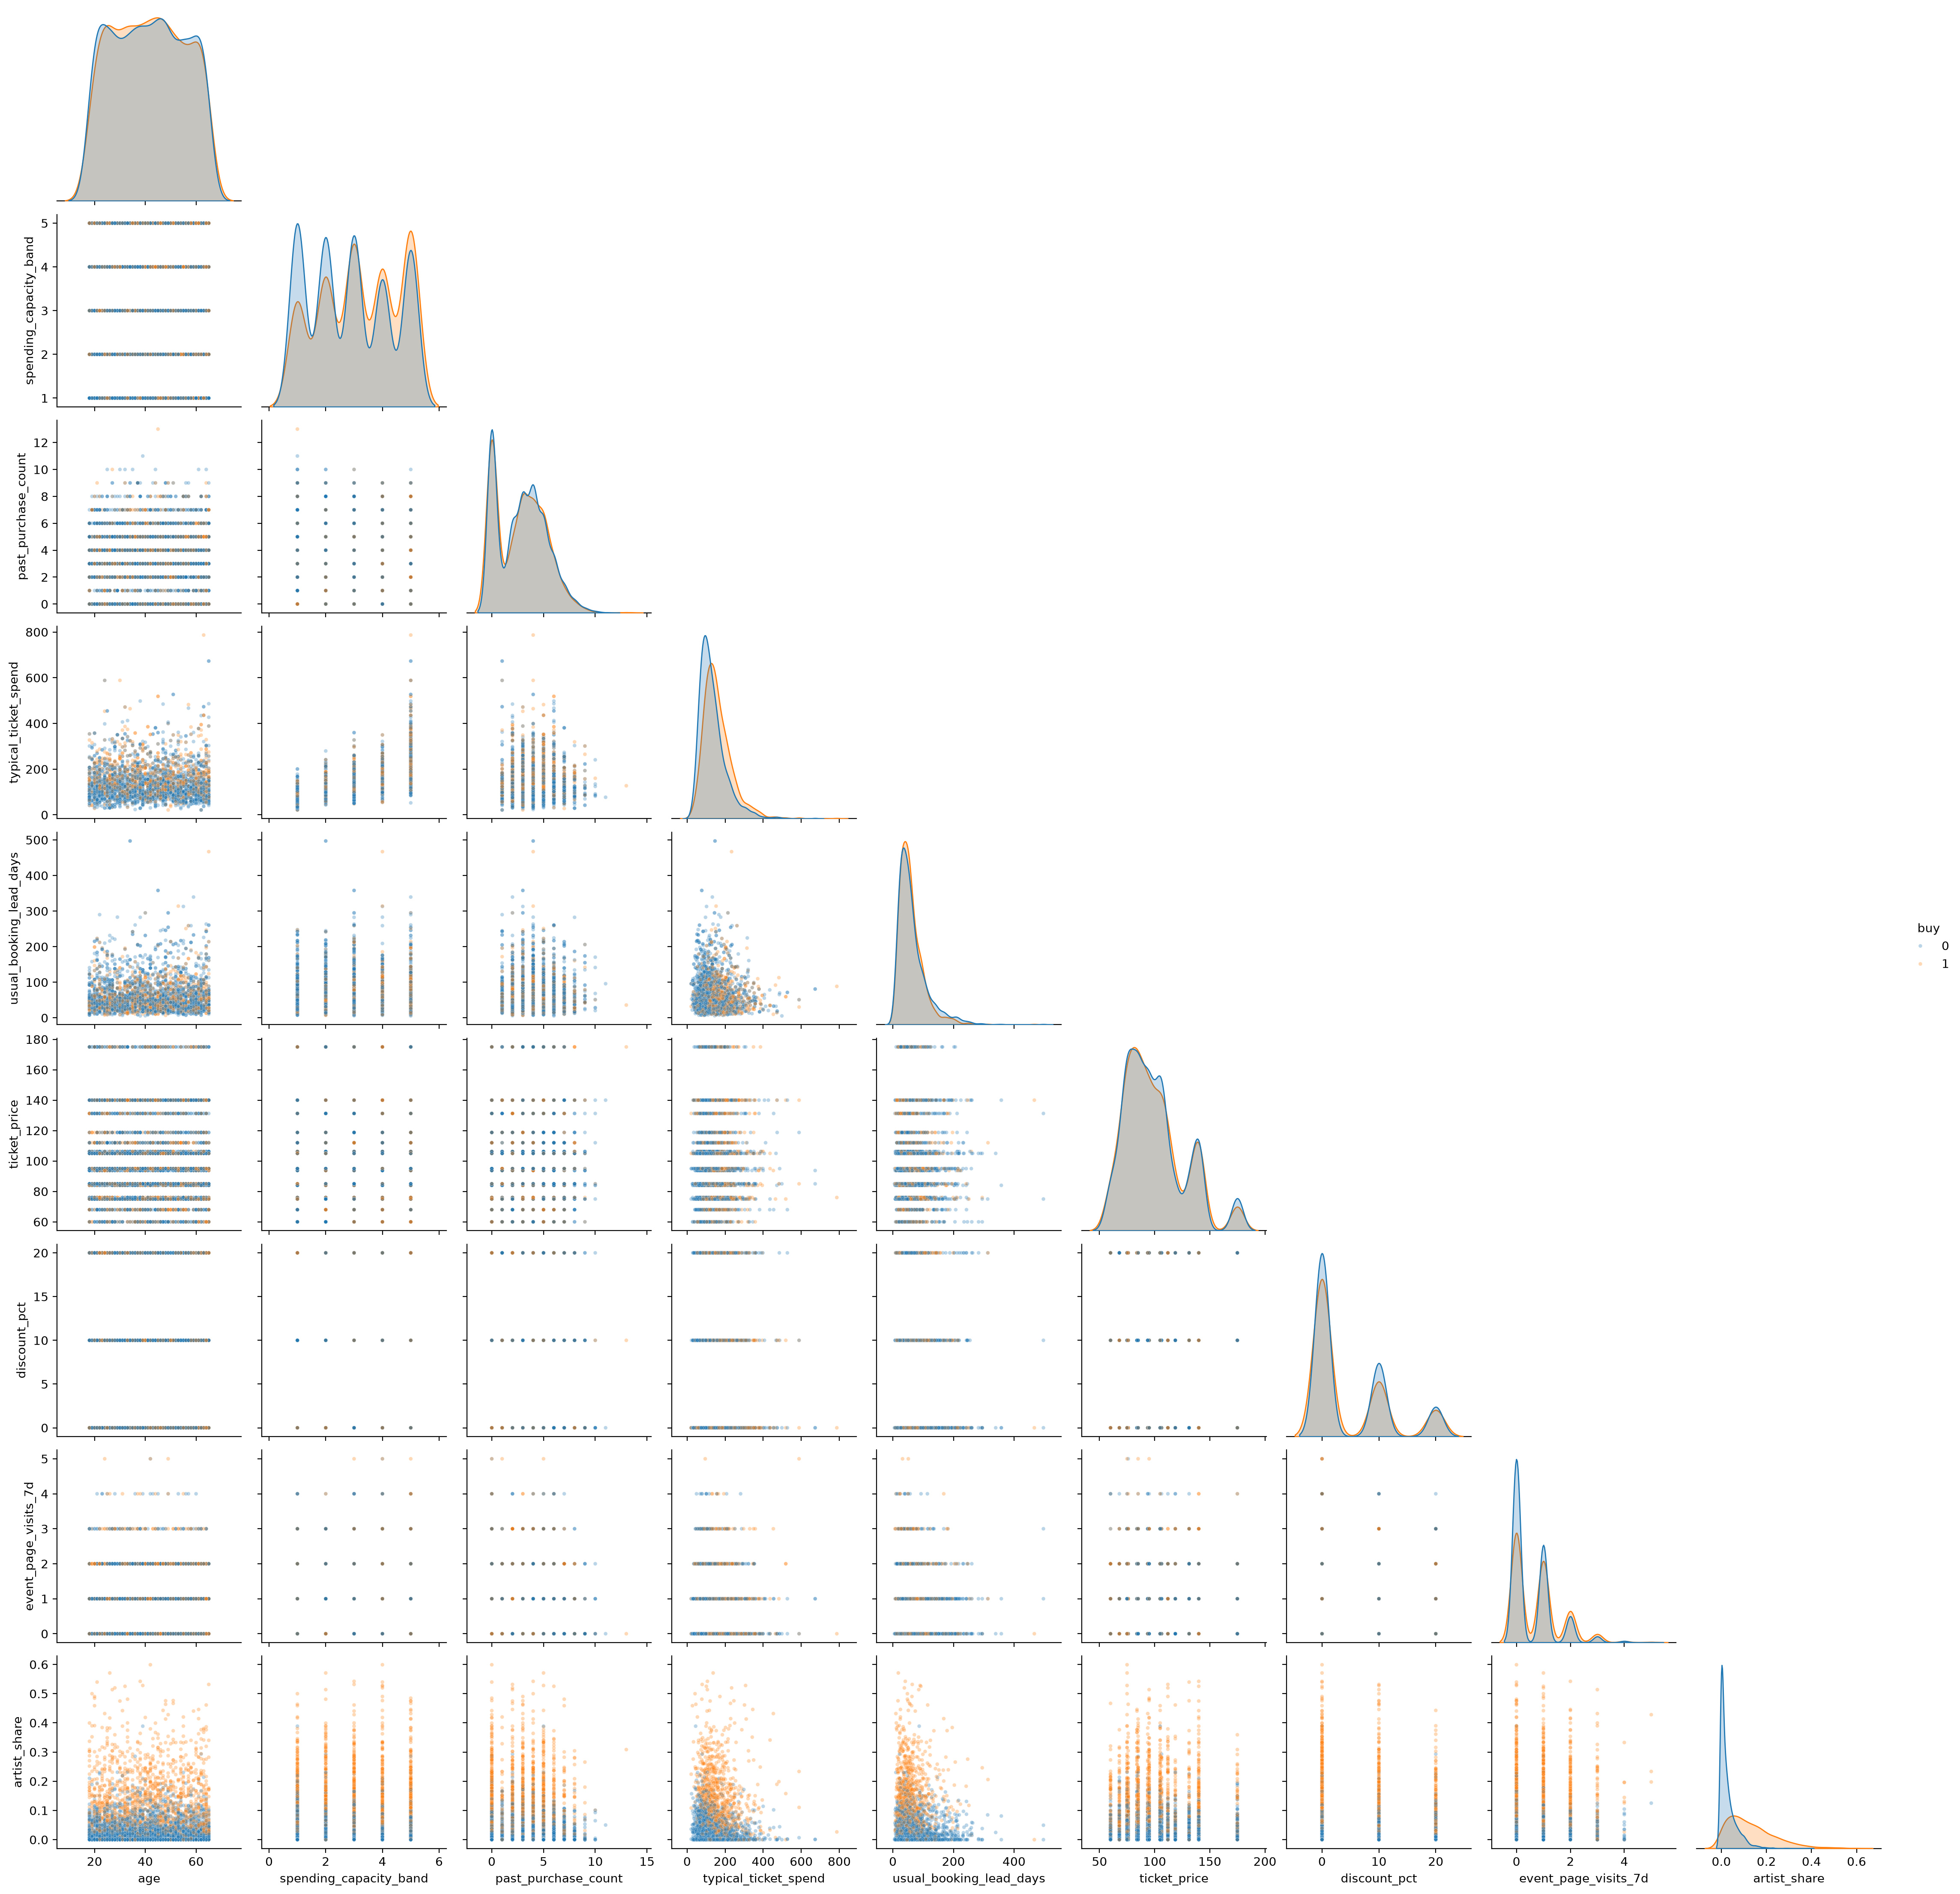

In [25]:
# same pairplot as before, now with artist_share (active users only, since only they have a share)
num_cols = ["age", "spending_capacity_band", "past_purchase_count", "typical_ticket_spend",
            "usual_booking_lead_days", "ticket_price", "discount_pct",
            "event_page_visits_7d", "artist_share"]

sb.pairplot(
    active[num_cols + ["buy"]].sample(5000, random_state=0),   # random sample to avoid 26k rows
    hue="buy", corner=True, plot_kws={"alpha": 0.3, "s": 10},
    diag_kws={"common_norm": False},                           # buyers' curve not shrunk because they're fewer
)

Only artist_share clearly separates buyers from non-buyers: non-buyers are piled at 0, buyers spread up to 60%, and this is also apparent across every other column (bottom row). Spending band, page visits and typical spend show smaller shifts. Age, past purchases, lead days and raw ticket price show none on their own. Ticket price has several peaks because each artist has its own prices, so price only makes sense relative to its concert. .. it’s the best clue in the whole dataset for guessing who buys. So in feature engineering,this is where we will put our effort

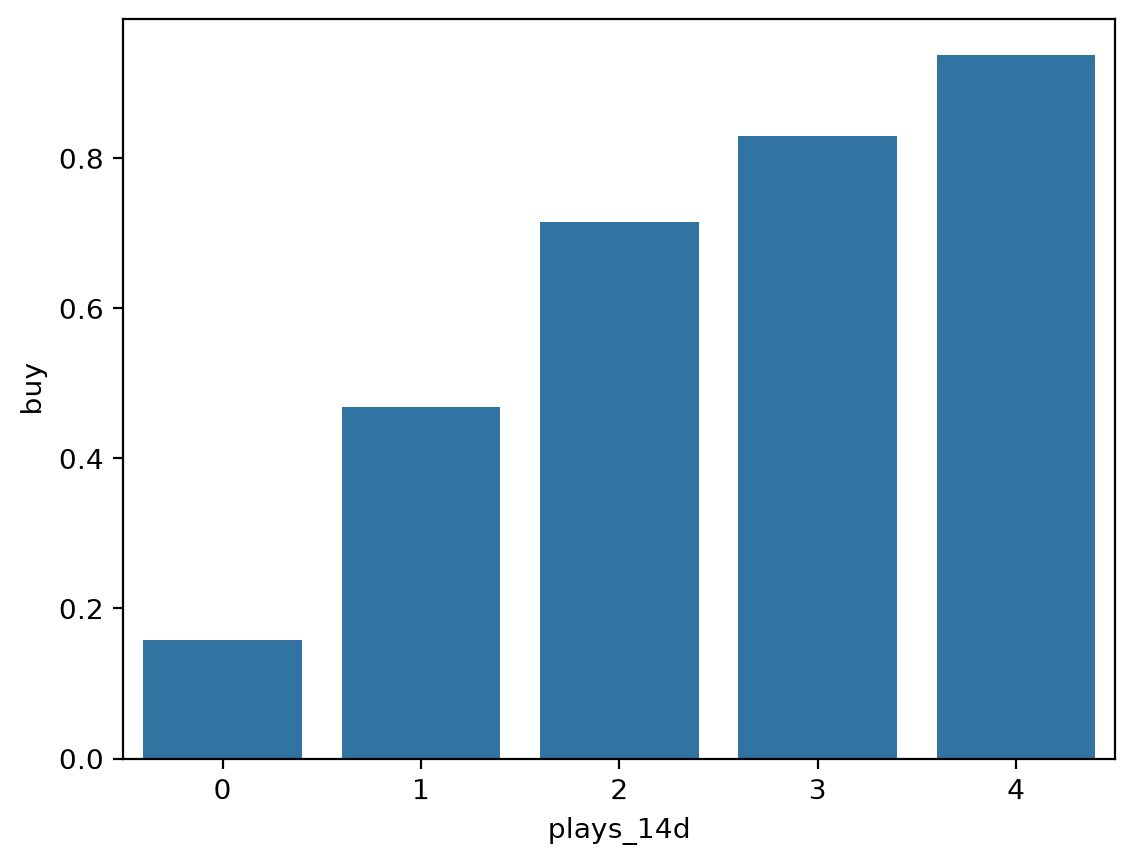

In [26]:
# does RECENT listening matter? buy rate by plays of the concert artist in the last 14 days
import json
with open("../data/raw/music_app.json") as f:
    listen = pd.json_normalize(json.load(f)["accounts"], record_path=["sessions", "tracks"], meta=["music_app_user_id"])

last_2w = listen[listen["played_at"] >= "2026-09-17"]                       # app data ends 30 Sep
counts = last_2w.groupby(["music_app_user_id", "artist_id"]).size().rename("plays_14d").reset_index()

rows = pd.read_csv("../data/raw/train.csv").merge(counts, on=["music_app_user_id", "artist_id"], how="left")
rows = rows[rows["music_app_user_id"].isin(listen["music_app_user_id"])]    # only users who use the app
rows["plays_14d"] = rows["plays_14d"].fillna(0).clip(upper=4).astype(int)   # 4 = "4 or more"

sb.barplot(data=rows, x="plays_14d", y="buy", errorbar=None)
plt.show()

the more they played the artist in the last 2 weeks, the more they buy: 16% with 0 plays ---> 94% with 4+. artist_share counts all 3 months the same, so it misses the “when” ---> recency features, built and tested in 03 modelling

### 2. stated_favourite_genre

for code bellow :  Missing genre looks random (34.6% vs 33.4%), so no flag needed.
... Fill with "unknown" instead of dropping rows: it keeps the data and invents nothing.

In [27]:
# 2. stated_favourite_genre
print(user_concert_train.groupby(user_concert_train["stated_favourite_genre"].isna())["buy"].mean())
# Missing genre is random: buy rate 34.6% when missing vs 33.4% when given, so no flag needed,
# instead of omitting, ill replace with unknown because we dont know its strength as a predictor variable
user_concert_train["stated_favourite_genre"] = user_concert_train["stated_favourite_genre"].fillna("unknown")
user_concert_test["stated_favourite_genre"]  = user_concert_test["stated_favourite_genre"].fillna("unknown")


stated_favourite_genre
False    0.334463
True     0.345730
Name: buy, dtype: float64


In [28]:
# does the user's favourite genre match one of the concert's genres?
genre_fit = [g in gs.split("|") for g, gs in zip(user_concert_train["stated_favourite_genre"],
                                                  user_concert_train["genres"])]
user_concert_train.groupby(pd.Series(genre_fit, name="genre_fits"))["buy"].mean()

genre_fits
False    0.295247
True     0.424776
Name: buy, dtype: float64

. People are more likely to go to a concert of the kind of music they like.

### 3. event_page_visits_7d

In [29]:
# do people with a missing visit count behave like people with 0 visits?
visits = user_concert_train["event_page_visits_7d"]
print("missing:", user_concert_train[visits.isna()]["buy"].mean())   # buy rate when the count is missing
print("0 visits:", user_concert_train[visits == 0]["buy"].mean())    # buy rate when they visited 0 times

missing: 0.3082271147161066
0 visits: 0.29247271825396826


In [30]:
# 3. event_page_visits_7d
print(user_concert_train.groupby(user_concert_train["event_page_visits_7d"].isna())["buy"].mean())
# Small gap: 30.8% when missing vs 33.7% -> keep a flag, fill with 0
user_concert_train["visits_missing"] = user_concert_train["event_page_visits_7d"].isna().astype(int)
user_concert_test["visits_missing"]  = user_concert_test["event_page_visits_7d"].isna().astype(int)
user_concert_train["event_page_visits_7d"] = user_concert_train["event_page_visits_7d"].fillna(0)
user_concert_test["event_page_visits_7d"]  = user_concert_test["event_page_visits_7d"].fillna(0)


#test
print(user_concert_train[["event_page_visits_7d", "visits_missing"]].head(10))

event_page_visits_7d
False    0.337029
True     0.308227
Name: buy, dtype: float64
   event_page_visits_7d  visits_missing
0                   0.0               0
1                   3.0               0
2                   1.0               0
3                   1.0               0
4                   0.0               0
5                   0.0               0
6                   0.0               0
7                   1.0               0
8                   2.0               0
9                   0.0               1


### 4. travel_search_city / travel_search_arrival

In [31]:
user_concert_train["travel_search_city"]

0           NaN
1           NaN
2           NaN
3           NaN
4        Rennes
          ...  
29995     Lille
29996       NaN
29997     Paris
29998     Lille
29999     Lille
Name: travel_search_city, Length: 30000, dtype: str

In [32]:
# 4. travel_search_city / travel_search_arrival
print(user_concert_train.groupby(user_concert_train["travel_search_city"].isna())["buy"].mean())
# Not random: people who searched travel buy 38.3% vs 32.1% who didn't -> keep a flag, leave the city/date empty (no "none")
user_concert_train["searched_travel"] = user_concert_train["travel_search_city"].notna().astype(int)
user_concert_test["searched_travel"]  = user_concert_test["travel_search_city"].notna().astype(int)


travel_search_city
False    0.383262
True     0.320501
Name: buy, dtype: float64


In [33]:

# days between the searched arrival and the concert (-1 = day before, 0 = same day, +1 = day after)
arrival = pd.to_datetime(user_concert_train["travel_search_arrival"])
concert = pd.to_datetime(user_concert_train["concert_at"].str[:10])   # keep only the date, drop the 20:00
gap = (arrival - concert).dt.days

# only searches to the concert's own city
same_city = user_concert_train["travel_search_city"] == user_concert_train["venue_city"]
user_concert_train[same_city].groupby(gap)["buy"].mean()

-18.0    0.097222
-17.0    0.090909
-16.0    0.115385
-15.0    0.098765
-14.0    0.217949
-13.0    0.065934
-12.0    0.140625
-11.0    0.115385
-10.0    0.129032
-9.0     0.074074
-8.0     0.120482
-7.0     0.067416
-1.0     0.716235
 0.0     0.736220
 1.0     0.745149
 7.0     0.073171
 8.0     0.065934
 9.0     0.076923
 10.0    0.121212
 11.0    0.146341
 12.0    0.177215
 13.0    0.147059
 14.0    0.086957
 15.0    0.057971
 16.0    0.062500
 17.0    0.125000
 18.0    0.128205
Name: buy, dtype: float64

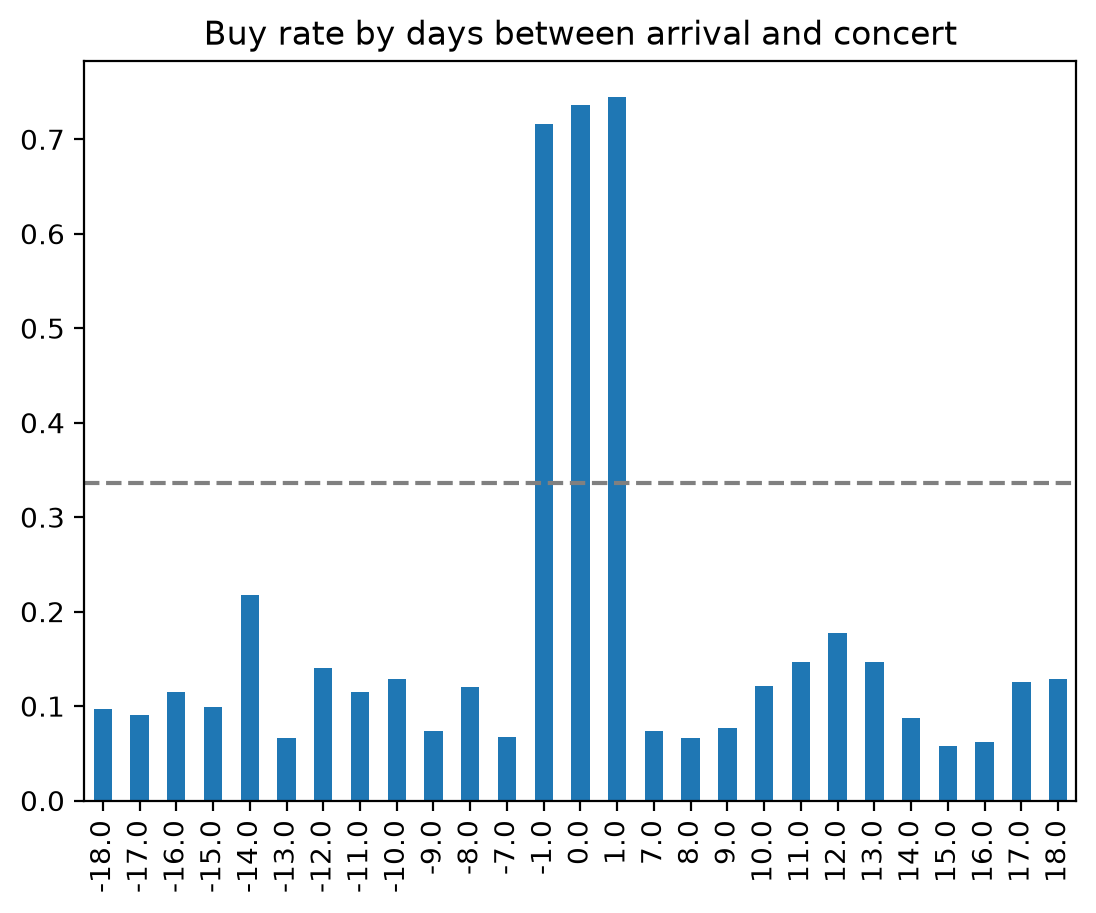

In [34]:
# buy rate by gap, for searches to the concert's city
user_concert_train[same_city].groupby(gap)["buy"].mean().plot(kind="bar", title="Buy rate by days between arrival and concert")
plt.axhline(user_concert_train["buy"].mean(), color="grey", linestyle="--")   # overall buy rate
plt.show()

Among people who searched for travel to the concert’s city, the dates decide everything. Those arriving the day before, the day of, or the day after the concert (−1, 0, +1) buy about 72–75% of the time, more than double the average (dashed line, 34%). Everyone arriving a week or more before or after buys only about 6–22%, below the average.

Decision: keep travel_search_city and travel_search_arrival (no “none” fill). In feature engineering, build a travel_date_match flag: searched the concert’s city and arrives within 1 day of the concert. It’s one of the strongest clues in the data, along with listening to the artist.

### 5. typical_ticket_spend / usual_booking_lead_days

In [35]:
# 5. typical_ticket_spend / usual_booking_lead_days
# are the missing values exactly the first-timers?
print(pd.crosstab(user_concert_train["typical_ticket_spend"].isna(), user_concert_train["first_timer"]))
# yes: first-timers have never bought, so these values don't exist for them
# -> leave them empty (no median fill); first_timer already marks these rows

first_timer               0     1
typical_ticket_spend             
False                 21760     0
True                      0  8240


## Spearman correlation heatmap

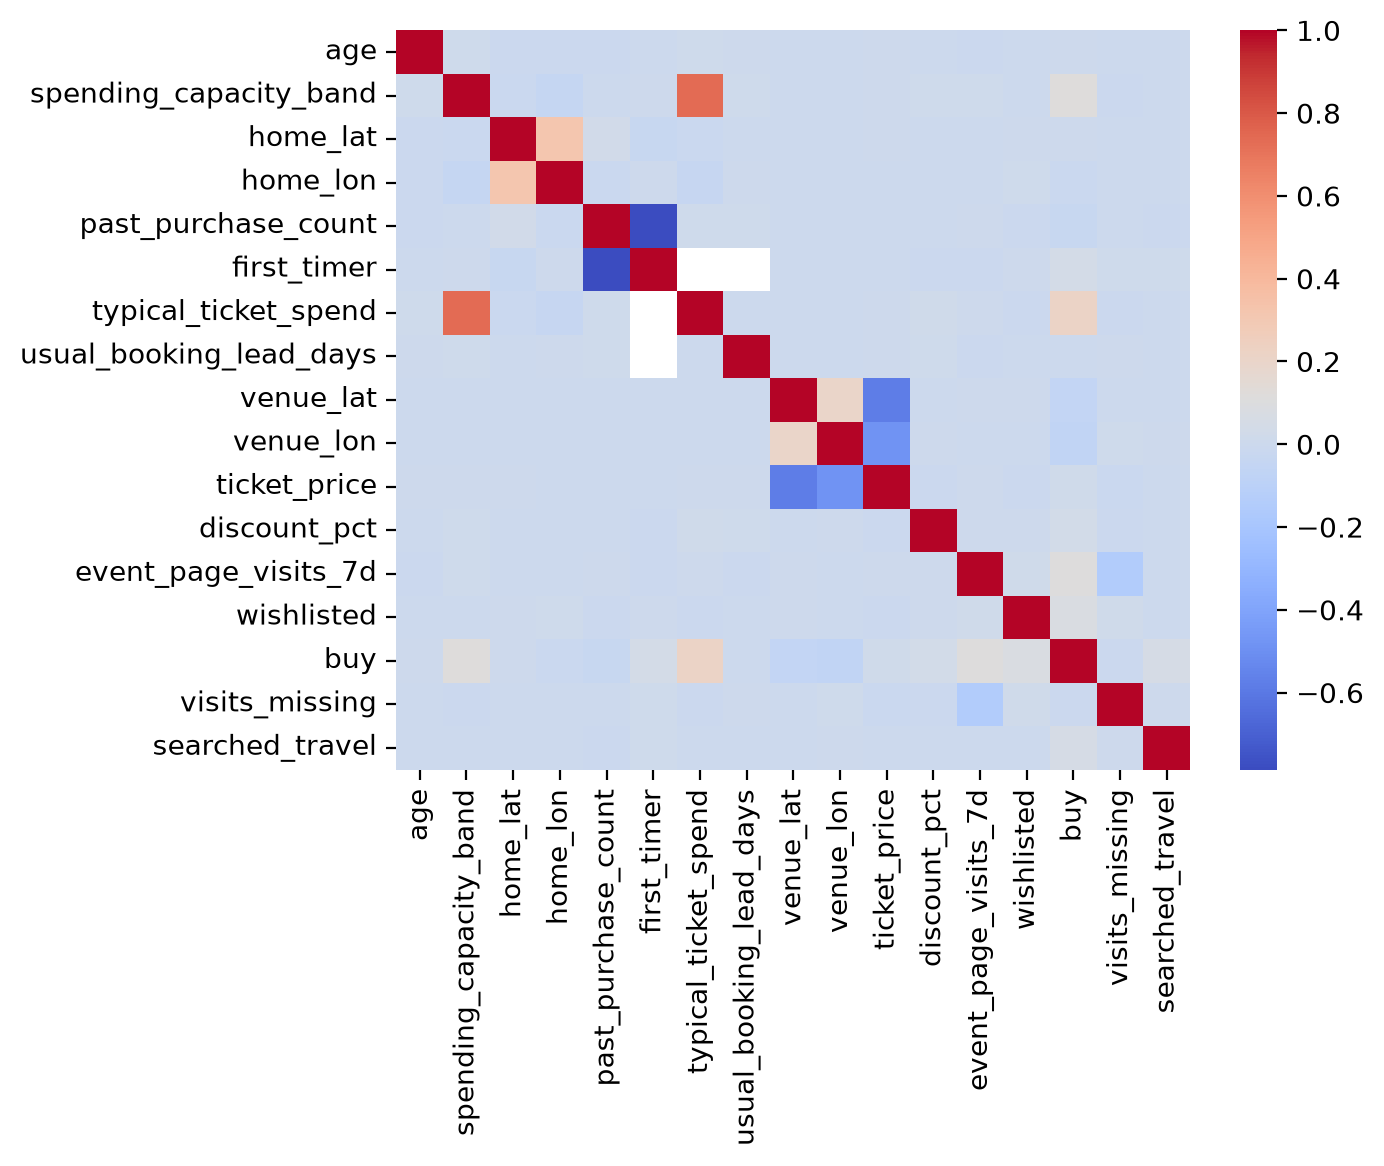

In [36]:
# use spearman because some distributions are skewed, using this to support my observations above (a,b,c,d)
sb.heatmap(user_concert_train.corr(method="spearman", numeric_only=True), cmap="coolwarm")
plt.show() 

the basic columns only give weak signals. The strong clues found in this EDA, listening to the concert’s artist (7% → 95%) and a travel search matching the concert (73% vs 10%), don’t appear here because they aren’t columns yet. Building them is the main job of feature engineering.

## Buy rate by categorical column

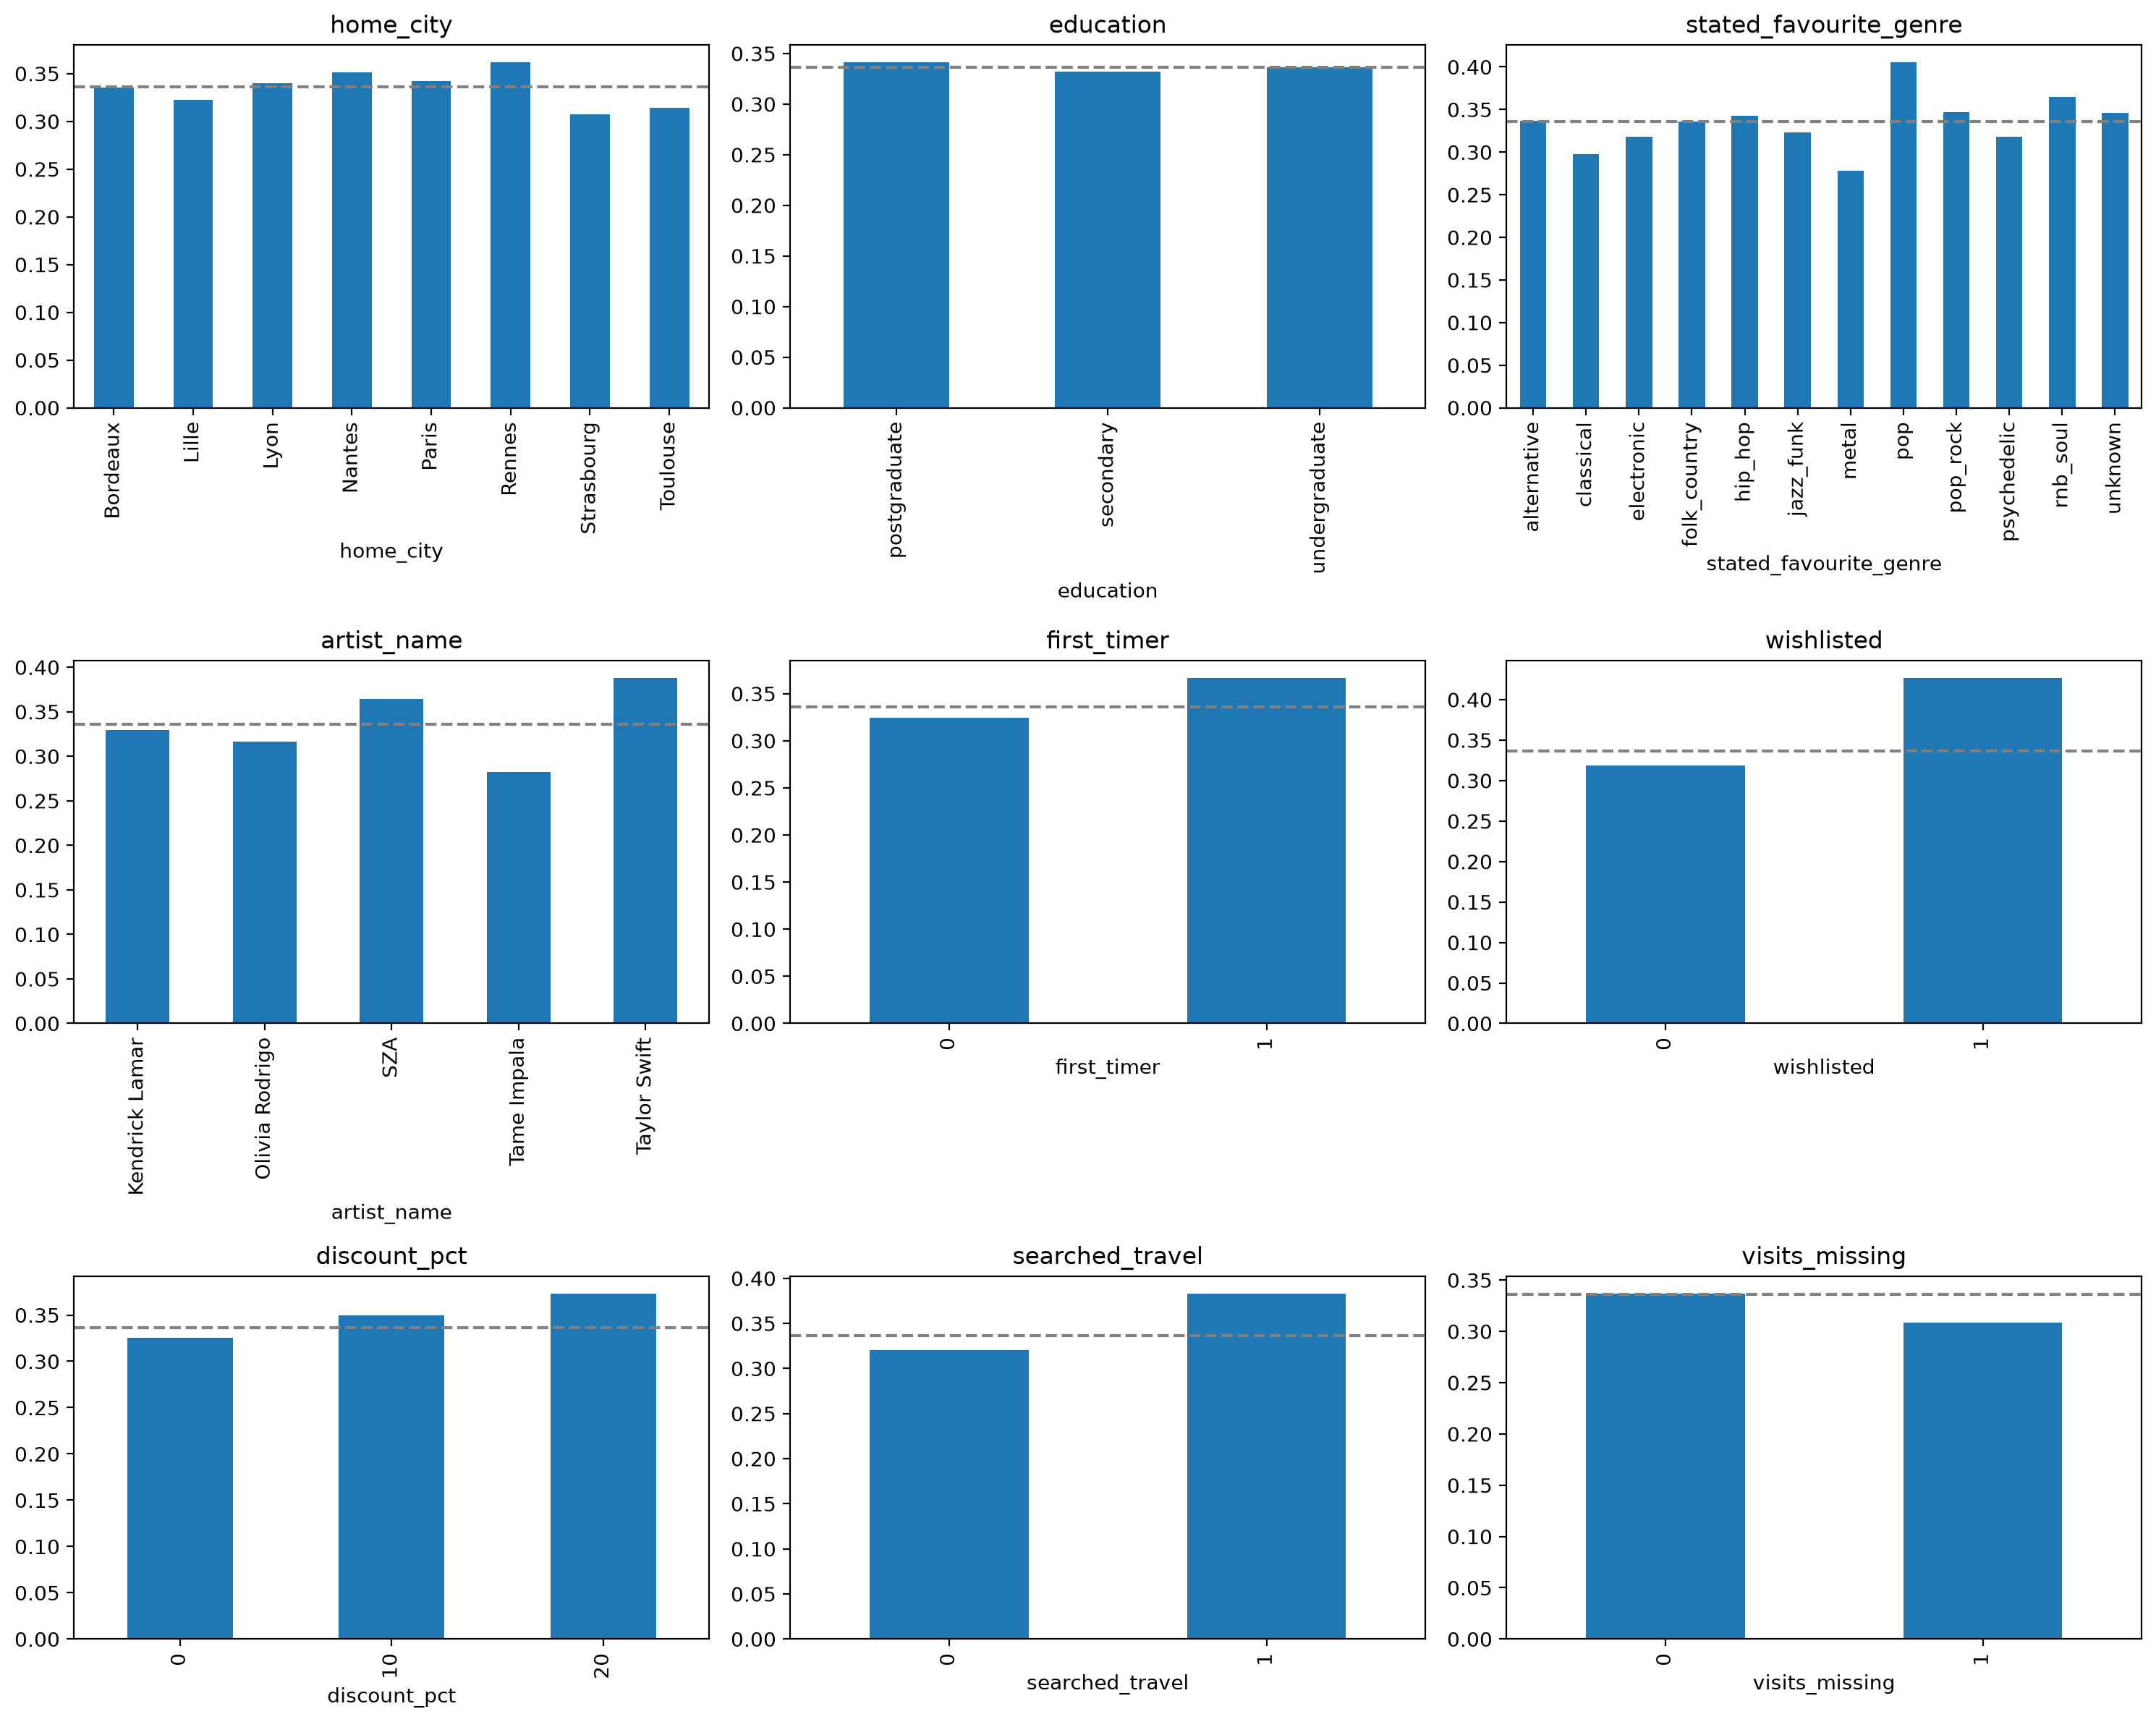

In [37]:
# categorical columns for analysis
cols = ["home_city", "education", "stated_favourite_genre", "artist_name",
        "first_timer", "wishlisted", "discount_pct", "searched_travel", "visits_missing"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))  # 3 rows x 3 columns
for col, ax in zip(cols, axes.flat):
    # buy rate per value: e.g. buyers in Bordeaux / all rows in Bordeaux
    user_concert_train.groupby(col)["buy"].mean().plot(kind="bar", ax=ax, title=col)
    ax.axhline(user_concert_train["buy"].mean(), color="grey", linestyle="--")  # overall buy rate
plt.tight_layout()
plt.show()

Wishlisted: 43% vs 32%, the clearest of these columns.
First-timers: buy a bit more (37% vs 32%).
Artist: Taylor Swift highest (39%), Tame Impala lowest (28%).
Discount: buying rises slightly with bigger discounts.
Favourite genre: pop fans buy most, metal and classical least. Whether the genre fits the concert matters more (42% vs 30%, see above).
Home city, education: small differences, weak on their own.
Searched travel: a small gap on its own. The real signal is when city and dates match the concert (see the travel section).

In [38]:
#Venue city looks identical as artist, just different permutation -- * ill do analysis on this
pd.crosstab(user_concert_train["artist_name"], user_concert_train["venue_city"])


venue_city,Bordeaux,Lille,Lyon,Nantes,Paris
artist_name,,,,,
Kendrick Lamar,0,0,0,0,6000
Olivia Rodrigo,0,0,6000,0,0
SZA,0,0,0,6000,0
Tame Impala,0,6000,0,0,0
Taylor Swift,6000,0,0,0,0


In [39]:
# is every concert column fixed per artist? (1 = one single value per artist)
user_concert_train.groupby("artist_name")[["venue_city", "concert_at", "genres", "concert_id"]].nunique()

,venue_city,concert_at,genres,concert_id
artist_name,,,,
Kendrick Lamar,1,1,1,1
Olivia Rodrigo,1,1,1,1
SZA,1,1,1,1
Tame Impala,1,1,1,1
Taylor Swift,1,1,1,1


##Final check: missing values left (all on purpose)

In [40]:
# only show columns that still have missing values
missing1 = user_concert_train.isnull().sum()
missing1[missing1 > 0]


music_app_user_id           1695
typical_ticket_spend        8240
usual_booking_lead_days     8240
travel_search_city         22496
travel_search_arrival      22496
dtype: int64

In [41]:
missing2 = user_concert_test.isnull().sum()
missing2[missing2 > 0]

music_app_user_id           1145
typical_ticket_spend        5775
usual_booking_lead_days     5775
travel_search_city         14955
travel_search_arrival      14955
dtype: int64

Only 5 columns are still empty, in both train and test, all on purpose: no music account, first-timers without purchase history, and rows without a travel search. Each case is already marked by another column (music_app_status, first_timer, searched_travel), and tree models handle empty values directly. Train and test have the same gaps in the same proportions, so they were cleaned the same way.

## Save the cleaned data
Used by `02_feature_engineering_constandino.ipynb` (the CSVs stay out of git thanks to `.gitignore`).

In [42]:
user_concert_train.to_csv("../data/processed/train_clean.csv", index=False)
user_concert_test.to_csv("../data/processed/test_clean.csv", index=False)
print(user_concert_train.shape, user_concert_test.shape)

(30000, 34) (20000, 33)


Summary of the EDA

One row = one user × one concert; 6,000 users × 5 concerts. Test users are all new, so validation must split by user.
Only 5 concerts: artist_name says everything about the concert, so no date features.
booking_fee is an exact copy of ticket_price, so it was dropped.
Music app: only active accounts have listening history. Empty, missing and no-account users buy about 50% vs 31% for active ones, so I keep music_app_status. For active users, listening to the concert’s artist predicts buying very strongly (7% if never, 95% above 20% of their listening).
Travel search: predicts buying only when it matches the concert’s city and dates (73% vs about 10%).
Weaker signals: wishlist (43% vs 32%), page visits (29% → 49%), genre fit (42% vs 30%), same city as the user, spending band.
Kept empty on purpose: first-timers’ spend and lead days, travel columns without a search, no music account.

Recent listening matters even more: buy rate goes 16% → 94% with plays of the artist in the last 14 days (0 vs 4+), which artist_share doesn’t capture → recency features, built and tested in 03 modelling.


For feature engineering: music features from the JSON (empty, not 0, for users without listening data), a travel city-and-date match, price_tier within each concert, genre_match, same_city.